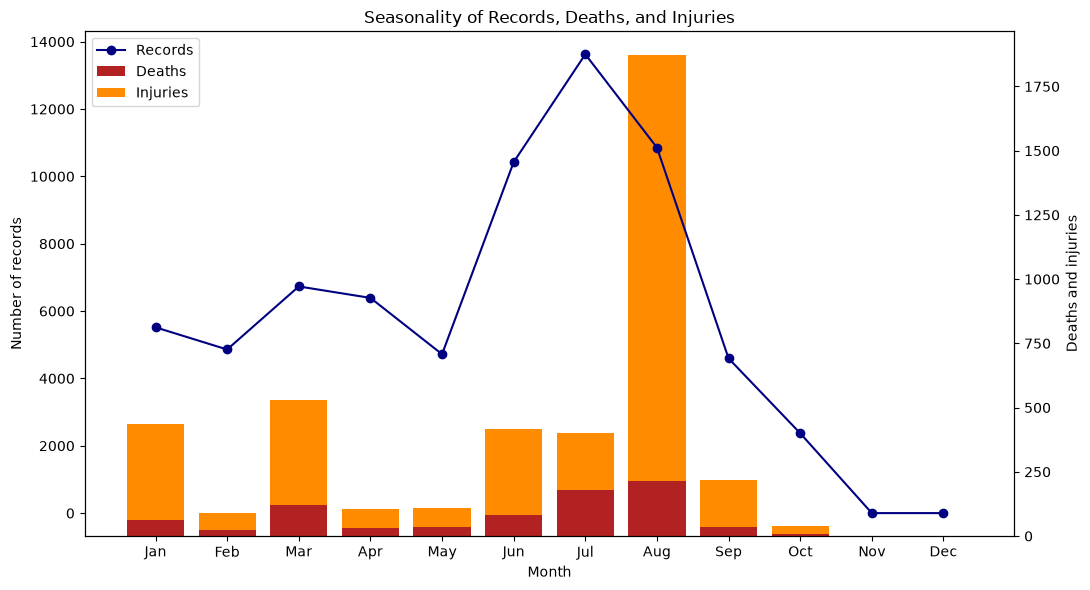

In [4]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Find data/data.db from the current notebook working directory or its parents.
database_path = None
for directory in (Path.cwd(), *Path.cwd().parents):
    candidate = directory / "data" / "data.db"
    if candidate.is_file():
        database_path = candidate
        break

if database_path is None:
    raise FileNotFoundError(f"Could not locate data/data.db from {Path.cwd()}")

query = """
SELECT
    BEGIN_DATE_TIME AS date,
    COALESCE(DEATHS_DIRECT, 0) + COALESCE(DEATHS_INDIRECT, 0) AS deaths,
    COALESCE(INJURIES_DIRECT, 0) + COALESCE(INJURIES_INDIRECT, 0) AS injuries
FROM StormEvents
"""
with sqlite3.connect(database_path) as connection:
    data = pd.read_sql_query(query, connection)

date_col = "date"
deaths_col = "deaths"
injuries_col = "injuries"

data[date_col] = pd.to_datetime(data[date_col], errors="coerce")
data = data.dropna(subset=[date_col])

# Aggregate across years by calendar month to show seasonality.
monthly = (
    data.assign(month=data[date_col].dt.month)
    .groupby("month")
    .agg(
        records=(date_col, "size"),
        deaths=(deaths_col, "sum"),
        injuries=(injuries_col, "sum"),
    )
    .reindex(range(1, 13), fill_value=0)
)

fig, ax1 = plt.subplots(figsize=(11, 6))
ax2 = ax1.twinx()
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

months = monthly.index
ax2.bar(months, monthly["deaths"], label="Deaths", color="firebrick")
ax2.bar(
    months,
    monthly["injuries"],
    bottom=monthly["deaths"],
    label="Injuries",
    color="darkorange",
)
ax1.plot(months, monthly["records"], marker="o", color="navy", label="Records", zorder=10)

ax1.set_xticks(months)
ax1.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of records")
ax2.set_ylabel("Deaths and injuries")
ax1.set_title("Seasonality of Records, Deaths, and Injuries")

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

In [5]:
# Investigate what drove the August spike in injuries and deaths
# Use the existing sqlite connection from the notebook.

august = pd.read_sql_query(
    """
    SELECT
        BEGIN_DATE_TIME AS date,
        STATE AS state,
        EVENT_TYPE AS event_type,
        COALESCE(DEATHS_DIRECT, 0) + COALESCE(DEATHS_INDIRECT, 0) AS deaths,
        COALESCE(INJURIES_DIRECT, 0) + COALESCE(INJURIES_INDIRECT, 0) AS injuries,
        COALESCE(DEATHS_DIRECT, 0) AS deaths_direct,
        COALESCE(DEATHS_INDIRECT, 0) AS deaths_indirect,
        COALESCE(INJURIES_DIRECT, 0) AS injuries_direct,
        COALESCE(INJURIES_INDIRECT, 0) AS injuries_indirect
    FROM StormEvents
    WHERE date(BEGIN_DATE_TIME) >= '2023-08-01'
      AND date(BEGIN_DATE_TIME) <  '2023-09-01'
    """,
    connection,
)

august["date"] = pd.to_datetime(august["date"], errors="coerce")
august = august.dropna(subset=["date"]).copy()

# Top event types by total injuries + deaths
by_event = (
    august.groupby("event_type", as_index=False)
    .agg(
        events=("date", "size"),
        deaths=("deaths", "sum"),
        injuries=("injuries", "sum"),
        deaths_direct=("deaths_direct", "sum"),
        deaths_indirect=("deaths_indirect", "sum"),
        injuries_direct=("injuries_direct", "sum"),
        injuries_indirect=("injuries_indirect", "sum"),
    )
    .assign(total_harm=lambda d: d["deaths"] + d["injuries"])
    .sort_values(["total_harm", "injuries", "deaths"], ascending=False)
)

print("Top event types in August:")
display(by_event.head(15))

# Top states by total harm
by_state = (
    august.groupby("state", as_index=False)
    .agg(
        events=("date", "size"),
        deaths=("deaths", "sum"),
        injuries=("injuries", "sum"),
    )
    .assign(total_harm=lambda d: d["deaths"] + d["injuries"])
    .sort_values(["total_harm", "injuries", "deaths"], ascending=False)
)

print("\nTop states in August:")
display(by_state.head(15))

# Show the most damaging August records for the largest driver
top_event = by_event.iloc[0]["event_type"]
top_event_records = (
    august[august["event_type"] == top_event]
    .sort_values(["injuries", "deaths"], ascending=False)
    .head(10)
)

print(f"\nTop August records for the largest driver: {top_event}")
display(
    top_event_records[
        ["date", "state", "event_type", "deaths", "injuries",
         "deaths_direct", "deaths_indirect", "injuries_direct", "injuries_indirect"]
    ]
)

# Optional: a month-to-month comparison for the same event type
monthly_event = (
    pd.read_sql_query(
        """
        SELECT
            CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) AS month,
            EVENT_TYPE AS event_type,
            COALESCE(DEATHS_DIRECT, 0) + COALESCE(DEATHS_INDIRECT, 0) AS deaths,
            COALESCE(INJURIES_DIRECT, 0) + COALESCE(INJURIES_INDIRECT, 0) AS injuries
        FROM StormEvents
        """,
        connection,
    )
    .groupby(["month", "event_type"], as_index=False)
    .agg(deaths=("deaths", "sum"), injuries=("injuries", "sum"))
)

top_event_monthly = monthly_event[monthly_event["event_type"] == top_event].sort_values("month")
print(f"\nMonthly pattern for {top_event}:")
display(top_event_monthly)

Top event types in August:


,event_type,events,deaths,injuries,deaths_direct,deaths_indirect,injuries_direct,injuries_indirect,total_harm
7,Excessive Heat,2753,51,1513,39,12,1513,0,1564
32,Wildfire,83,102,55,102,0,32,23,157
27,Thunderstorm Wind,3686,9,39,8,1,38,1,48
12,Heat,1067,39,0,29,10,0,0,39
16,Lightning,47,4,19,4,0,18,1,23
28,Tornado,138,2,15,2,0,15,0,17
15,Hurricane,11,1,8,1,0,7,1,9
30,Tropical Storm,171,3,2,1,2,1,1,5
8,Flash Flood,581,2,2,2,0,2,0,4
11,Hail,904,0,2,0,0,2,0,2



Top states in August:


,state,events,deaths,injuries,total_harm
54,TEXAS,958,21,1338,1359
15,HAWAII,22,100,32,132
35,MISSOURI,297,0,92,92
46,OKLAHOMA,798,1,91,92
2,ARIZONA,140,52,0,52
0,ALABAMA,621,1,23,24
6,CALIFORNIA,218,1,23,24
12,GEORGIA,794,2,11,13
32,MICHIGAN,86,7,4,11
38,NEVADA,33,11,0,11



Top August records for the largest driver: Excessive Heat


,date,state,event_type,deaths,injuries,deaths_direct,deaths_indirect,injuries_direct,injuries_indirect
10835,2023-08-17 12:00:00,TEXAS,Excessive Heat,0,806,0,0,806,0
9885,2023-08-01 12:00:00,TEXAS,Excessive Heat,0,467,0,0,467,0
10831,2023-08-19 10:00:00,OKLAHOMA,Excessive Heat,0,45,0,0,45,0
4857,2023-08-20 10:00:00,MISSOURI,Excessive Heat,0,44,0,0,44,0
4858,2023-08-20 10:00:00,MISSOURI,Excessive Heat,0,43,0,0,43,0
10751,2023-08-01 12:00:00,TEXAS,Excessive Heat,1,34,1,0,34,0
9965,2023-08-01 10:00:00,OKLAHOMA,Excessive Heat,0,32,0,0,32,0
9755,2023-08-17 12:00:00,TEXAS,Excessive Heat,1,31,1,0,31,0
10356,2023-08-11 11:00:00,OKLAHOMA,Excessive Heat,0,6,0,0,6,0
10559,2023-08-13 11:00:00,OKLAHOMA,Excessive Heat,0,5,0,0,5,0



Monthly pattern for Excessive Heat:


,month,event_type,deaths,injuries
166,6,Excessive Heat,20,17
194,7,Excessive Heat,103,96
221,8,Excessive Heat,51,1513
254,9,Excessive Heat,4,0


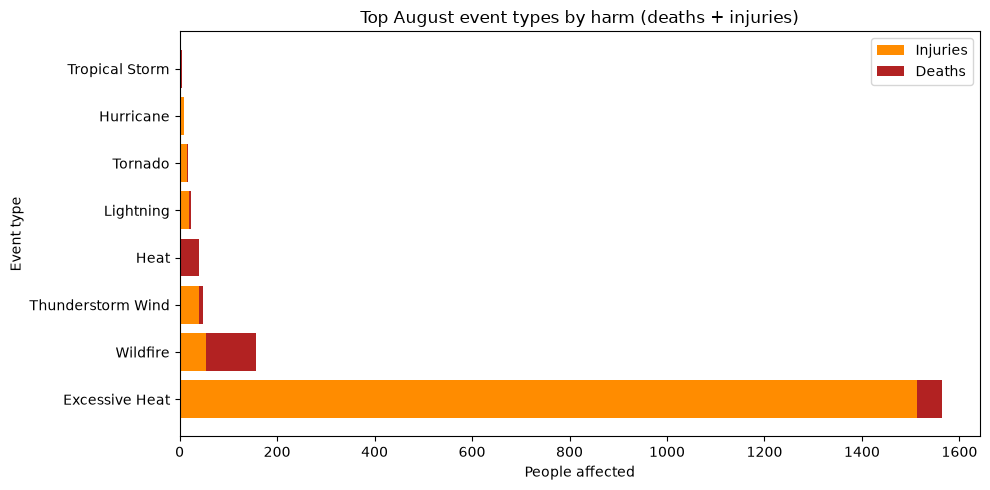

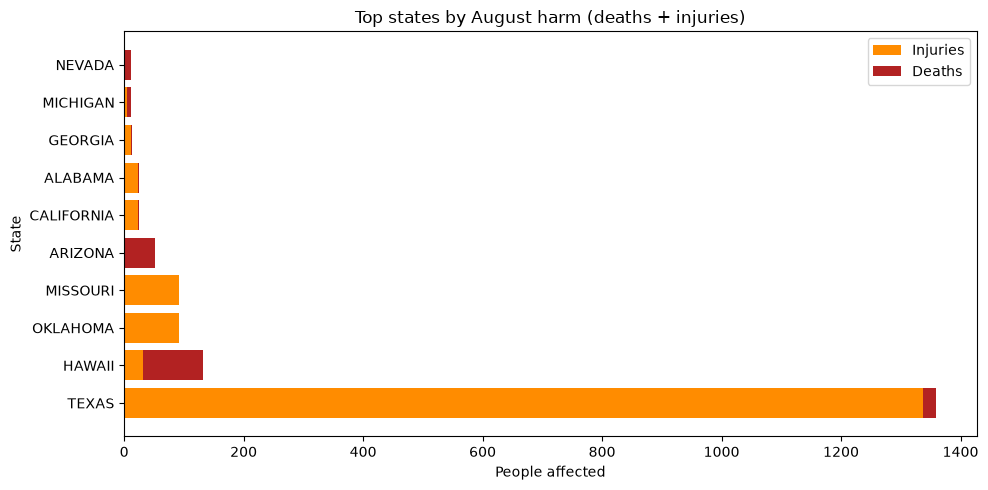

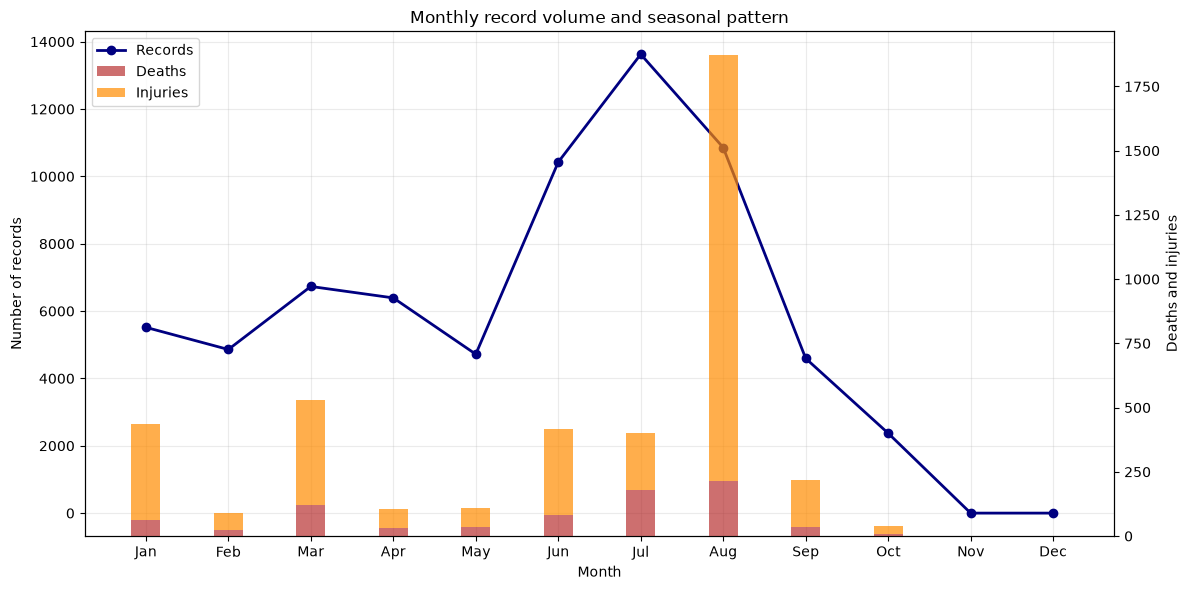

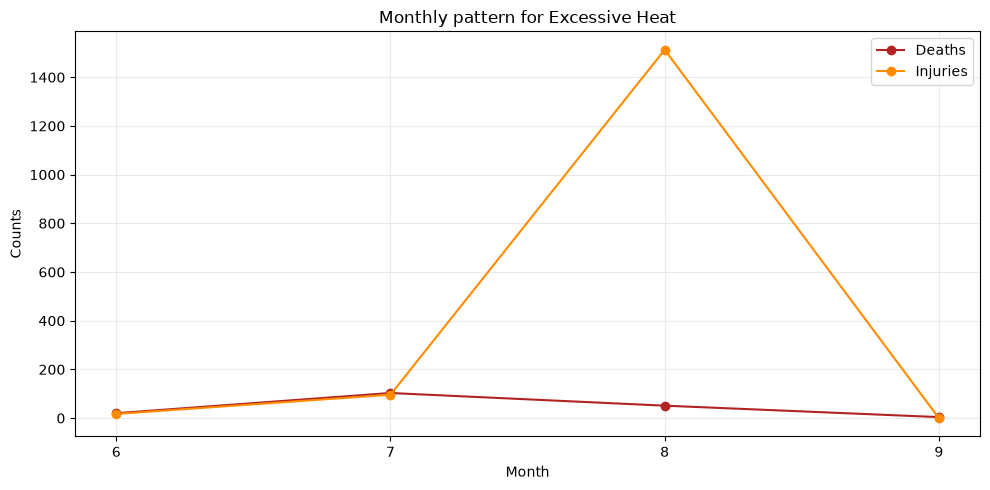

In [6]:
import numpy as np

import matplotlib.pyplot as plt

# -----------------------------
# 1) Top event types by total harm
# -----------------------------
event_chart = by_event.head(8).sort_values("total_harm", ascending=True).copy()
event_chart["total_harm"] = event_chart["deaths"] + event_chart["injuries"]

fig1, ax1 = plt.subplots(figsize=(10, 5))
y = np.arange(len(event_chart))
ax1.barh(y, event_chart["injuries"], color="darkorange", label="Injuries")
ax1.barh(y, event_chart["deaths"], left=event_chart["injuries"], color="firebrick", label="Deaths")
ax1.set_yticks(y)
ax1.set_yticklabels(event_chart["event_type"])
ax1.invert_yaxis()
ax1.set_xlabel("People affected")
ax1.set_ylabel("Event type")
ax1.set_title("Top August event types by harm (deaths + injuries)")
ax1.legend(loc="upper right")
plt.tight_layout()
plt.show()

# -----------------------------
# 2) Top states by total harm
# -----------------------------
state_chart = by_state.head(10).sort_values("total_harm", ascending=True).copy()
state_chart["total_harm"] = state_chart["deaths"] + state_chart["injuries"]

fig2, ax2 = plt.subplots(figsize=(10, 5))
y = np.arange(len(state_chart))
ax2.barh(y, state_chart["injuries"], color="darkorange", label="Injuries")
ax2.barh(y, state_chart["deaths"], left=state_chart["injuries"], color="firebrick", label="Deaths")
ax2.set_yticks(y)
ax2.set_yticklabels(state_chart["state"])
ax2.invert_yaxis()
ax2.set_xlabel("People affected")
ax2.set_ylabel("State")
ax2.set_title("Top states by August harm (deaths + injuries)")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

# -----------------------------
# 3) Monthly seasonality plot
# -----------------------------
fig3, ax3 = plt.subplots(figsize=(12, 6))
ax3.plot(monthly.index, monthly["records"], marker="o", color="navy", linewidth=2, label="Records")
ax3.set_xlabel("Month")
ax3.set_ylabel("Number of records")
ax3.set_xticks(range(1, 13))
ax3.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax3.set_title("Monthly record volume and seasonal pattern")
ax3.grid(alpha=0.25)

ax4 = ax3.twinx()
ax4.bar(monthly.index, monthly["deaths"], width=0.35, color="firebrick", alpha=0.65, label="Deaths")
ax4.bar(monthly.index, monthly["injuries"], width=0.35, color="darkorange", alpha=0.7, bottom=monthly["deaths"], label="Injuries")
ax4.set_ylabel("Deaths and injuries")
handles1, labels1 = ax3.get_legend_handles_labels()
handles2, labels2 = ax4.get_legend_handles_labels()
ax3.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()

# -----------------------------
# 4) Monthly pattern for the largest driver
# -----------------------------
top_monthly = top_event_monthly.copy()
fig4, ax5 = plt.subplots(figsize=(10, 5))
ax5.plot(top_monthly["month"], top_monthly["deaths"], marker="o", color="firebrick", label="Deaths")
ax5.plot(top_monthly["month"], top_monthly["injuries"], marker="o", color="darkorange", label="Injuries")
ax5.set_xlabel("Month")
ax5.set_ylabel("Counts")
ax5.set_xticks(top_monthly["month"])
ax5.set_title(f"Monthly pattern for {top_event}")
ax5.grid(alpha=0.25)
ax5.legend()
plt.tight_layout()
plt.show()

Top event types in Jun-Aug 2023:


,event_type,events,deaths,injuries,deaths_direct,deaths_indirect,injuries_direct,injuries_indirect,total_harm
10,Excessive Heat,4589,174,1626,122,52,1626,0,1800
34,Tornado,506,10,165,10,0,165,0,175
17,Heat,2784,100,60,70,30,60,0,160
39,Wildfire,162,102,56,102,0,33,23,158
33,Thunderstorm Wind,14377,23,118,22,1,110,8,141
16,Hail,5807,0,92,0,0,92,0,92
22,Lightning,178,7,52,6,1,43,9,59
30,Rip Current,61,30,8,30,0,8,0,38
12,Flash Flood,1901,16,6,16,0,6,0,22
21,Hurricane,11,1,8,1,0,7,1,9



Top states in Jun-Aug 2023:


,state,events,deaths,injuries,total_harm
55,TEXAS,3506,67,1555,1622
3,ARIZONA,313,161,6,167
36,MISSOURI,1016,4,146,150
16,HAWAII,41,100,38,138
47,OKLAHOMA,2225,3,125,128
8,COLORADO,1046,4,96,100
39,NEVADA,109,39,0,39
7,CALIFORNIA,472,6,26,32
12,FLORIDA,925,19,13,32
0,ALABAMA,1349,3,25,28



Top Jun-Aug records for the largest driver: Excessive Heat


,date,state,event_type,deaths,injuries,deaths_direct,deaths_indirect,injuries_direct,injuries_indirect
34872,2023-08-17 12:00:00,TEXAS,Excessive Heat,0,806,0,0,806,0
32663,2023-08-01 12:00:00,TEXAS,Excessive Heat,0,467,0,0,467,0
34868,2023-08-19 10:00:00,OKLAHOMA,Excessive Heat,0,45,0,0,45,0
23438,2023-08-20 10:00:00,MISSOURI,Excessive Heat,0,44,0,0,44,0
23439,2023-08-20 10:00:00,MISSOURI,Excessive Heat,0,43,0,0,43,0
34700,2023-08-01 12:00:00,TEXAS,Excessive Heat,1,34,1,0,34,0
32895,2023-08-01 10:00:00,OKLAHOMA,Excessive Heat,0,32,0,0,32,0
32290,2023-08-17 12:00:00,TEXAS,Excessive Heat,1,31,1,0,31,0
33479,2023-07-27 09:00:00,MISSOURI,Excessive Heat,0,25,0,0,25,0
33480,2023-07-27 09:00:00,MISSOURI,Excessive Heat,0,25,0,0,25,0



Monthly pattern for Excessive Heat (Jun-Aug):


,month,event_type,deaths,injuries
0,6,Excessive Heat,20,17
1,7,Excessive Heat,103,96
2,8,Excessive Heat,51,1513


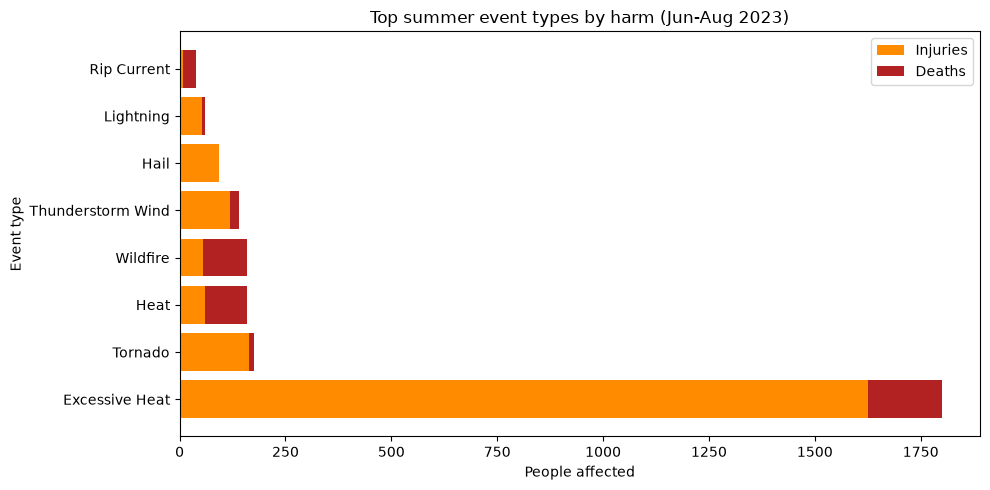

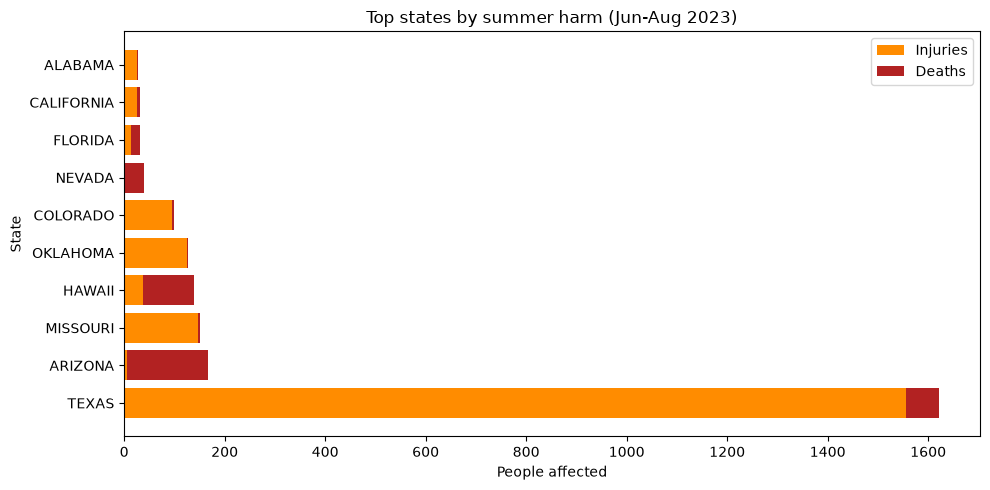

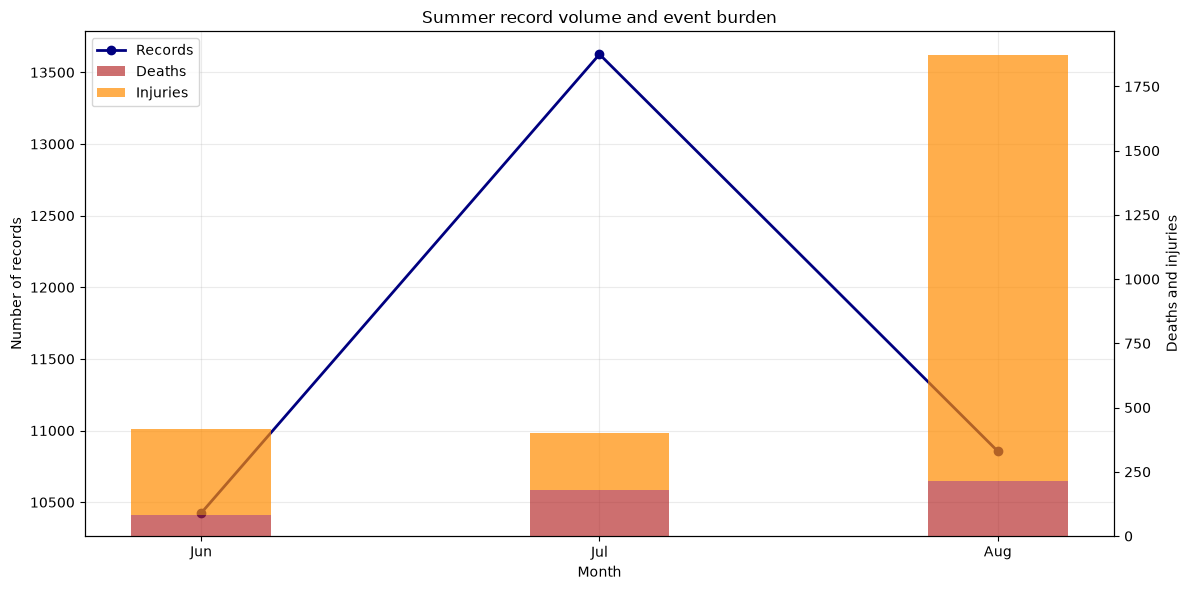

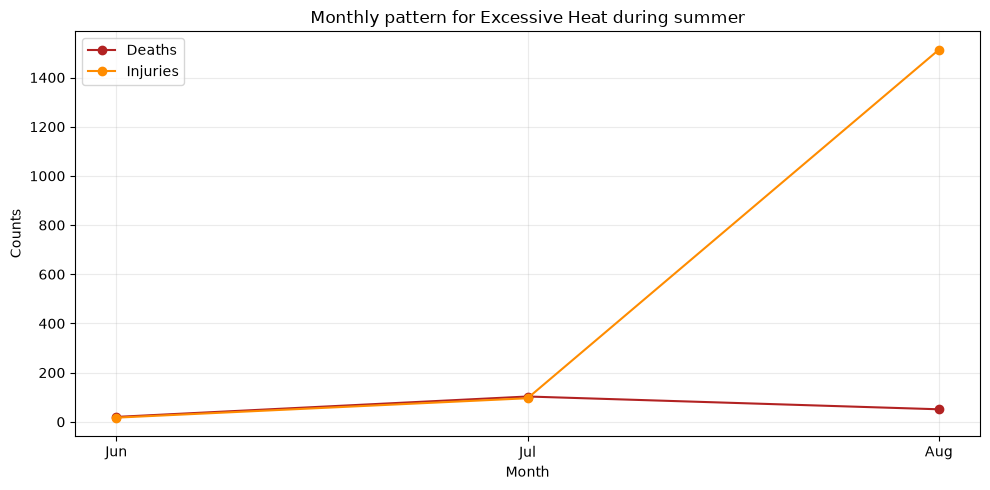

In [7]:
# June-July-August 2023 analysis
# Reuse the existing SQLite connection and imported pandas/matplotlib/numpy

summer = pd.read_sql_query(
    """
    SELECT
        BEGIN_DATE_TIME AS date,
        STATE AS state,
        EVENT_TYPE AS event_type,
        COALESCE(DEATHS_DIRECT, 0) + COALESCE(DEATHS_INDIRECT, 0) AS deaths,
        COALESCE(INJURIES_DIRECT, 0) + COALESCE(INJURIES_INDIRECT, 0) AS injuries,
        COALESCE(DEATHS_DIRECT, 0) AS deaths_direct,
        COALESCE(DEATHS_INDIRECT, 0) AS deaths_indirect,
        COALESCE(INJURIES_DIRECT, 0) AS injuries_direct,
        COALESCE(INJURIES_INDIRECT, 0) AS injuries_indirect
    FROM StormEvents
    WHERE date(BEGIN_DATE_TIME) >= '2023-06-01'
      AND date(BEGIN_DATE_TIME) <  '2023-09-01'
    """,
    connection,
)

summer["date"] = pd.to_datetime(summer["date"], errors="coerce")
summer = summer.dropna(subset=["date"]).copy()

# Top event types by total harm across June-August
by_event = (
    summer.groupby("event_type", as_index=False)
    .agg(
        events=("date", "size"),
        deaths=("deaths", "sum"),
        injuries=("injuries", "sum"),
        deaths_direct=("deaths_direct", "sum"),
        deaths_indirect=("deaths_indirect", "sum"),
        injuries_direct=("injuries_direct", "sum"),
        injuries_indirect=("injuries_indirect", "sum"),
    )
    .assign(total_harm=lambda d: d["deaths"] + d["injuries"])
    .sort_values(["total_harm", "injuries", "deaths"], ascending=False)
)

print("Top event types in Jun-Aug 2023:")
display(by_event.head(15))

# Top states by total harm
by_state = (
    summer.groupby("state", as_index=False)
    .agg(
        events=("date", "size"),
        deaths=("deaths", "sum"),
        injuries=("injuries", "sum"),
    )
    .assign(total_harm=lambda d: d["deaths"] + d["injuries"])
    .sort_values(["total_harm", "injuries", "deaths"], ascending=False)
)

print("\nTop states in Jun-Aug 2023:")
display(by_state.head(15))

# Show the most damaging summer records for the largest driver
top_event = by_event.iloc[0]["event_type"]
top_event_records = (
    summer[summer["event_type"] == top_event]
    .sort_values(["injuries", "deaths"], ascending=False)
    .head(10)
)

print(f"\nTop Jun-Aug records for the largest driver: {top_event}")
display(
    top_event_records[
        ["date", "state", "event_type", "deaths", "injuries",
         "deaths_direct", "deaths_indirect", "injuries_direct", "injuries_indirect"]
    ]
)

# Monthly pattern for the biggest driver across June/July/August
monthly_event = (
    pd.read_sql_query(
        """
        SELECT
            CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) AS month,
            EVENT_TYPE AS event_type,
            COALESCE(DEATHS_DIRECT, 0) + COALESCE(DEATHS_INDIRECT, 0) AS deaths,
            COALESCE(INJURIES_DIRECT, 0) + COALESCE(INJURIES_INDIRECT, 0) AS injuries
        FROM StormEvents
        WHERE date(BEGIN_DATE_TIME) >= '2023-06-01'
          AND date(BEGIN_DATE_TIME) <  '2023-09-01'
        """,
        connection,
    )
    .groupby(["month", "event_type"], as_index=False)
    .agg(deaths=("deaths", "sum"), injuries=("injuries", "sum"))
)

top_event_monthly = (
    monthly_event[monthly_event["event_type"] == top_event]
    .sort_values("month")
    .reset_index(drop=True)
)

print(f"\nMonthly pattern for {top_event} (Jun-Aug):")
display(top_event_monthly)

# Monthly summer volume counts
summer_monthly = (
    summer.assign(month=summer["date"].dt.month)
    .groupby("month")
    .agg(
        records=("date", "size"),
        deaths=("deaths", "sum"),
        injuries=("injuries", "sum"),
    )
    .reindex([6, 7, 8], fill_value=0)
)

# -----------------------------
# 1) Top event types by total harm
# -----------------------------
event_chart = by_event.head(8).sort_values("total_harm", ascending=True).copy()
event_chart["total_harm"] = event_chart["deaths"] + event_chart["injuries"]

fig1, ax1 = plt.subplots(figsize=(10, 5))
y = np.arange(len(event_chart))
ax1.barh(y, event_chart["injuries"], color="darkorange", label="Injuries")
ax1.barh(y, event_chart["deaths"], left=event_chart["injuries"], color="firebrick", label="Deaths")
ax1.set_yticks(y)
ax1.set_yticklabels(event_chart["event_type"])
ax1.invert_yaxis()
ax1.set_xlabel("People affected")
ax1.set_ylabel("Event type")
ax1.set_title("Top summer event types by harm (Jun-Aug 2023)")
ax1.legend(loc="upper right")
plt.tight_layout()
plt.show()

# -----------------------------
# 2) Top states by total harm
# -----------------------------
state_chart = by_state.head(10).sort_values("total_harm", ascending=True).copy()
state_chart["total_harm"] = state_chart["deaths"] + state_chart["injuries"]

fig2, ax2 = plt.subplots(figsize=(10, 5))
y = np.arange(len(state_chart))
ax2.barh(y, state_chart["injuries"], color="darkorange", label="Injuries")
ax2.barh(y, state_chart["deaths"], left=state_chart["injuries"], color="firebrick", label="Deaths")
ax2.set_yticks(y)
ax2.set_yticklabels(state_chart["state"])
ax2.invert_yaxis()
ax2.set_xlabel("People affected")
ax2.set_ylabel("State")
ax2.set_title("Top states by summer harm (Jun-Aug 2023)")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

# -----------------------------
# 3) Summer monthly volume & harm
# -----------------------------
fig3, ax3 = plt.subplots(figsize=(12, 6))
ax3.plot(summer_monthly.index, summer_monthly["records"], marker="o", color="navy", linewidth=2, label="Records")
ax3.set_xlabel("Month")
ax3.set_ylabel("Number of records")
ax3.set_xticks([6, 7, 8])
ax3.set_xticklabels(["Jun", "Jul", "Aug"])
ax3.set_title("Summer record volume and event burden")
ax3.grid(alpha=0.25)

ax4 = ax3.twinx()
ax4.bar(summer_monthly.index, summer_monthly["deaths"], width=0.35, color="firebrick", alpha=0.65, label="Deaths")
ax4.bar(summer_monthly.index, summer_monthly["injuries"], width=0.35, color="darkorange", alpha=0.7, bottom=summer_monthly["deaths"], label="Injuries")
ax4.set_ylabel("Deaths and injuries")

handles1, labels1 = ax3.get_legend_handles_labels()
handles2, labels2 = ax4.get_legend_handles_labels()
ax3.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
plt.tight_layout()
plt.show()

# -----------------------------
# 4) Monthly pattern for the largest driver across the summer
# -----------------------------
fig4, ax5 = plt.subplots(figsize=(10, 5))
ax5.plot(top_event_monthly["month"], top_event_monthly["deaths"], marker="o", color="firebrick", label="Deaths")
ax5.plot(top_event_monthly["month"], top_event_monthly["injuries"], marker="o", color="darkorange", label="Injuries")
ax5.set_xlabel("Month")
ax5.set_ylabel("Counts")
ax5.set_xticks([6, 7, 8])
ax5.set_xticklabels(["Jun", "Jul", "Aug"])
ax5.set_title(f"Monthly pattern for {top_event} during summer")
ax5.grid(alpha=0.25)
ax5.legend()
plt.tight_layout()
plt.show()

In [8]:
# Investigate the Jan and Mar spikes in the monthly record counts
# Uses the existing SQLite connection and notebook variables

jan_mar = pd.read_sql_query(
    """
    SELECT
        CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) AS month,
        STATE AS state,
        EVENT_TYPE AS event_type,
        COALESCE(DEATHS_DIRECT, 0) + COALESCE(DEATHS_INDIRECT, 0) AS deaths,
        COALESCE(INJURIES_DIRECT, 0) + COALESCE(INJURIES_INDIRECT, 0) AS injuries
    FROM StormEvents
    WHERE CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) IN (1, 3)
    """,
    connection,
)

jan_mar["month_name"] = jan_mar["month"].map({1: "Jan", 3: "Mar"})

# Top event types in Jan and Mar
top_events = (
    jan_mar.groupby(["month_name", "event_type"], as_index=False)
    .agg(
        events=("event_type", "size"),
        deaths=("deaths", "sum"),
        injuries=("injuries", "sum"),
    )
    .assign(total_harm=lambda d: d["deaths"] + d["injuries"])
    .sort_values(["month_name", "total_harm"], ascending=[True, False])
)

print("Top event types in Jan and Mar:")
display(top_events.head(30))

# Top states in Jan and Mar
top_states = (
    jan_mar.groupby(["month_name", "state"], as_index=False)
    .agg(
        events=("event_type", "size"),
        deaths=("deaths", "sum"),
        injuries=("injuries", "sum"),
    )
    .assign(total_harm=lambda d: d["deaths"] + d["injuries"])
    .sort_values(["month_name", "total_harm"], ascending=[True, False])
)

print("\nTop states in Jan and Mar:")
display(top_states.head(30))

# Show the biggest contributors in each month
for month_name in ["Jan", "Mar"]:
    print(f"\n=== {month_name} top event types by event count ===")
    display(
        top_events[top_events["month_name"] == month_name]
        .sort_values(["events", "total_harm"], ascending=[False, False])
        .head(10)
    )

Top event types in Jan and Mar:


,month_name,event_type,events,deaths,injuries,total_harm
28,Jan,Tornado,166,15,137,152
32,Jan,Winter Weather,936,15,99,114
31,Jan,Winter Storm,844,3,98,101
4,Jan,Cold/Wind Chill,22,4,8,12
26,Jan,Strong Wind,200,6,6,12
17,Jan,Heavy Snow,652,0,7,7
10,Jan,Flash Flood,183,5,1,6
18,Jan,High Surf,26,0,6,6
24,Jan,Rip Current,3,3,3,6
1,Jan,Avalanche,5,3,2,5



Top states in Jan and Mar:


,month_name,state,events,deaths,injuries,total_harm
12,Jan,GEORGIA,233,8,103,111
56,Jan,WISCONSIN,103,4,53,57
50,Jan,TEXAS,277,7,47,54
31,Jan,MISSOURI,163,1,48,49
57,Jan,WYOMING,139,1,40,41
0,Jan,ALABAMA,140,7,20,27
7,Jan,CALIFORNIA,1023,14,9,23
21,Jan,KENTUCKY,155,2,10,12
24,Jan,LOUISIANA,85,0,9,9
15,Jan,HAWAII,23,1,6,7



=== Jan top event types by event count ===


,month_name,event_type,events,deaths,injuries,total_harm
32,Jan,Winter Weather,936,15,99,114
31,Jan,Winter Storm,844,3,98,101
17,Jan,Heavy Snow,652,0,7,7
27,Jan,Thunderstorm Wind,528,1,2,3
11,Jan,Flood,502,5,0,5
19,Jan,High Wind,434,0,0,0
7,Jan,Drought,375,0,0,0
26,Jan,Strong Wind,200,6,6,12
10,Jan,Flash Flood,183,5,1,6
28,Jan,Tornado,166,15,137,152



=== Mar top event types by event count ===


,month_name,event_type,events,deaths,injuries,total_harm
60,Mar,Thunderstorm Wind,1137,4,18,22
50,Mar,High Wind,867,10,12,22
46,Mar,Hail,808,0,0,0
48,Mar,Heavy Snow,665,2,6,8
65,Mar,Winter Weather,628,7,26,33
42,Mar,Flood,555,10,2,12
64,Mar,Winter Storm,500,2,1,3
39,Mar,Drought,312,0,0,0
61,Mar,Tornado,266,47,295,342
41,Mar,Flash Flood,242,4,2,6


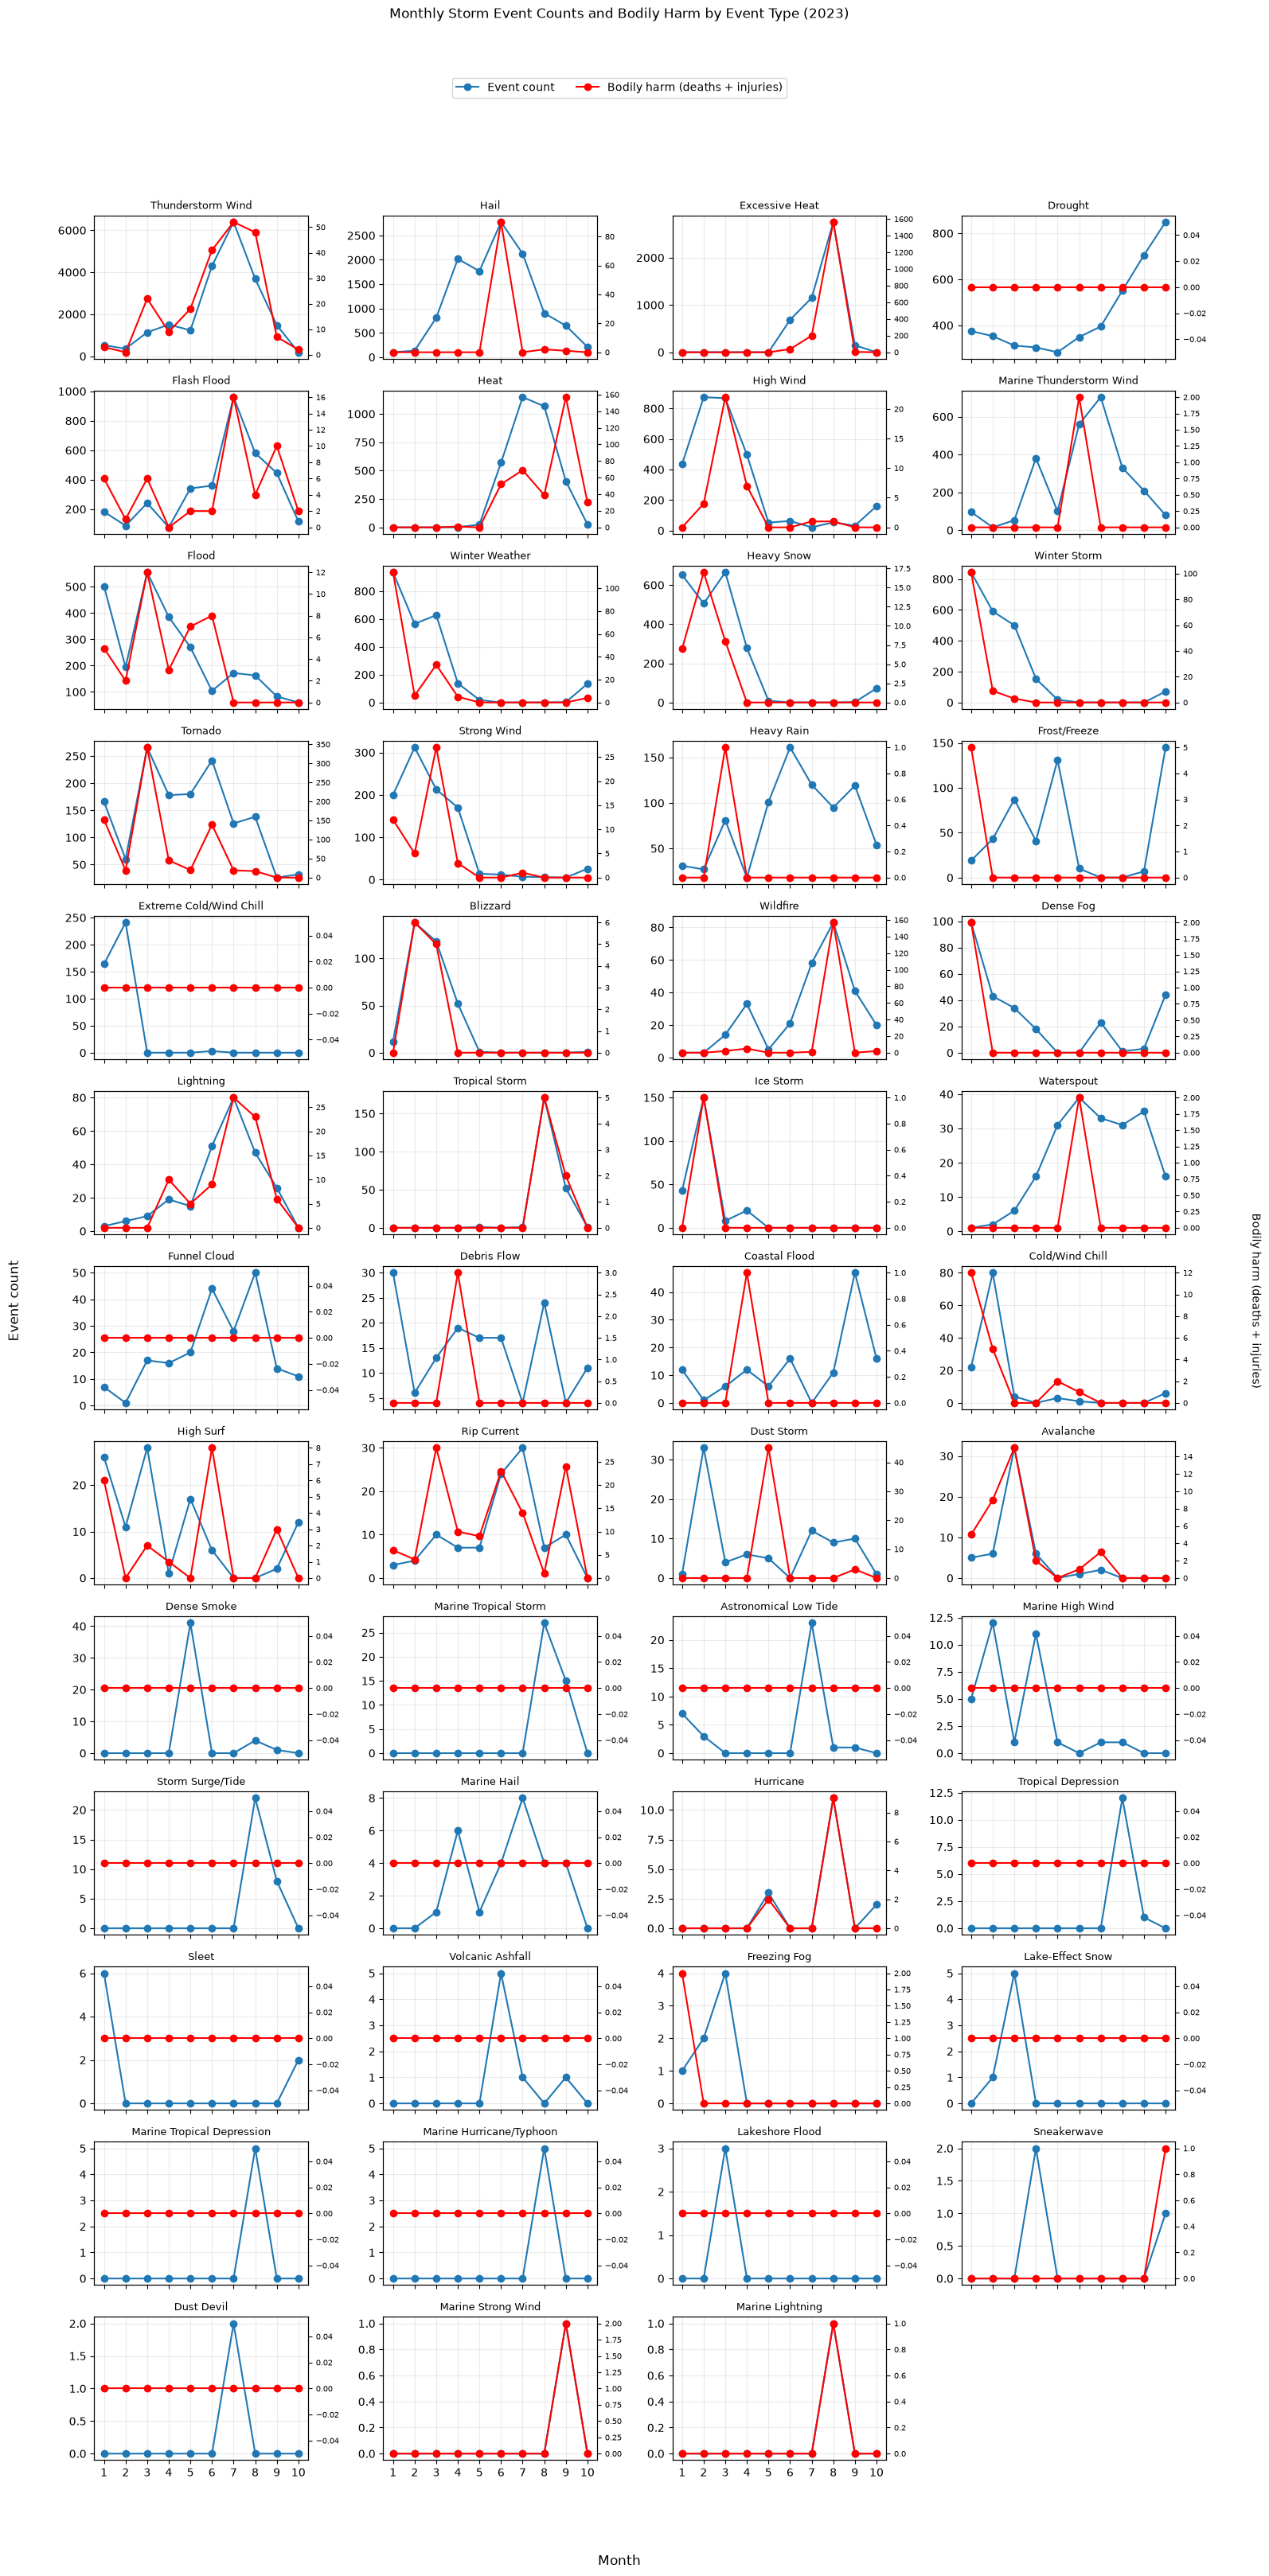

In [10]:
seasonality = pd.read_sql_query(
    """
    SELECT
        CAST(strftime('%m', BEGIN_DATE_TIME) AS INTEGER) AS month,
        EVENT_TYPE AS event_type,
        COUNT(*) AS events,
        SUM(
            COALESCE(INJURIES_DIRECT, 0)
            + COALESCE(INJURIES_INDIRECT, 0)
            + COALESCE(DEATHS_DIRECT, 0)
            + COALESCE(DEATHS_INDIRECT, 0)
        ) AS bodily_harm
    FROM StormEvents
    WHERE date(BEGIN_DATE_TIME) >= '2023-01-01'
      AND date(BEGIN_DATE_TIME) <  '2024-01-01'
    GROUP BY month, event_type
    """,
    connection,
)

seasonality = seasonality.dropna(subset=["month", "event_type"])
seasonality["month"] = seasonality["month"].astype(int)

if seasonality.empty:
    print("No 2023 event records found.")
else:
    last_month = seasonality["month"].max()
    event_types = (
        seasonality.groupby("event_type")["events"]
        .sum()
        .sort_values(ascending=False)
        .index
    )

    seasonality_pivot = (
        seasonality.pivot(index="event_type", columns="month", values="events")
        .reindex(index=event_types, columns=range(1, last_month + 1))
        .fillna(0)
    )
    bodily_harm_pivot = (
        seasonality.pivot(index="event_type", columns="month", values="bodily_harm")
        .reindex(index=event_types, columns=range(1, last_month + 1))
        .fillna(0)
    )

    columns = 4
    rows = (len(event_types) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows, columns, figsize=(16, rows * 2.5), sharex=True, squeeze=False
    )

    for ax, event_type in zip(axes.flat, event_types):
        event_line, = ax.plot(
            seasonality_pivot.columns,
            seasonality_pivot.loc[event_type],
            marker="o",
            linewidth=1.5,
        )
        harm_ax = ax.twinx()
        harm_ax.set_zorder(ax.get_zorder() + 1)
        ax.patch.set_visible(False)
        harm_line, = harm_ax.plot(
            bodily_harm_pivot.columns,
            bodily_harm_pivot.loc[event_type],
            color="red",
            marker="o",
            linewidth=1.5,
            zorder=10,
        )
        ax.set_title(event_type, fontsize=9)
        ax.set_xticks(range(1, last_month + 1))
        harm_ax.tick_params(axis="y", labelsize=7)
        ax.grid(alpha=0.25)

    for ax in axes.flat[len(event_types):]:
        ax.remove()

    fig.suptitle("Monthly Storm Event Counts and Bodily Harm by Event Type (2023)", y=1.0)
    fig.legend(
        [event_line, harm_line],
        ["Event count", "Bodily harm (deaths + injuries)"],
        loc="upper center",
        bbox_to_anchor=(0.5, 0.975),
        ncol=2,
    )
    fig.supxlabel("Month")
    fig.supylabel("Event count")
    fig.text(0.995, 0.5, "Bodily harm (deaths + injuries)", rotation=-90, va="center")
    fig.tight_layout(rect=(0.03, 0.03, 0.97, 0.94))
    plt.show()

,events,harmful_events,probability_pct,ci_95_pct
event_type,,,,
Rip Current,61,29,47.5,"[35.5%, 59.8%]"
Lightning,178,37,20.8,"[15.5%, 27.3%]"
Wildfire,162,5,3.1,"[1.3%, 7.0%]"
Tropical Storm,172,5,2.9,"[1.2%, 6.6%]"
Tornado,506,14,2.8,"[1.7%, 4.6%]"
Heat,2784,47,1.7,"[1.3%, 2.2%]"
Excessive Heat,4589,74,1.6,"[1.3%, 2.0%]"
High Wind,138,2,1.4,"[0.4%, 5.1%]"
Waterspout,103,1,1.0,"[0.2%, 5.3%]"


,event_type,events,harmful_events,probability_pct,ci_95_pct
0,Rip Current,102,69,67.6,"[58.1%, 75.9%]"
1,Avalanche,52,18,34.6,"[23.2%, 48.2%]"
2,Lightning,258,51,19.8,"[15.4%, 25.1%]"
3,Cold/Wind Chill,116,10,8.6,"[4.7%, 15.1%]"
4,Tornado,1414,90,6.4,"[5.2%, 7.8%]"
5,High Surf,103,6,5.8,"[2.7%, 12.1%]"
6,Wildfire,281,11,3.9,"[2.2%, 6.9%]"
7,Strong Wind,965,31,3.2,"[2.3%, 4.5%]"
8,Tropical Storm,226,7,3.1,"[1.5%, 6.3%]"
9,Dust Storm,81,2,2.5,"[0.7%, 8.6%]"


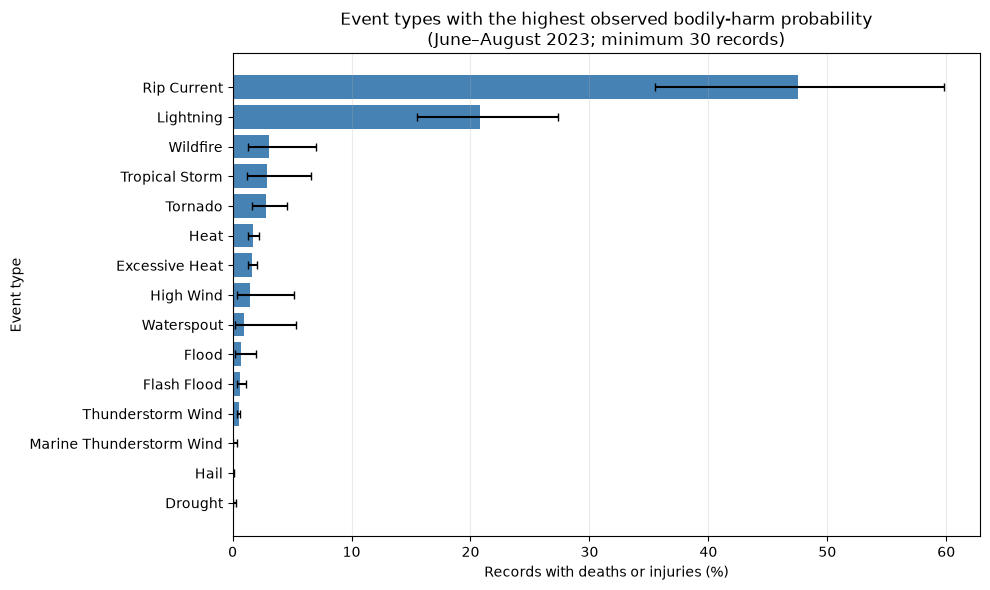

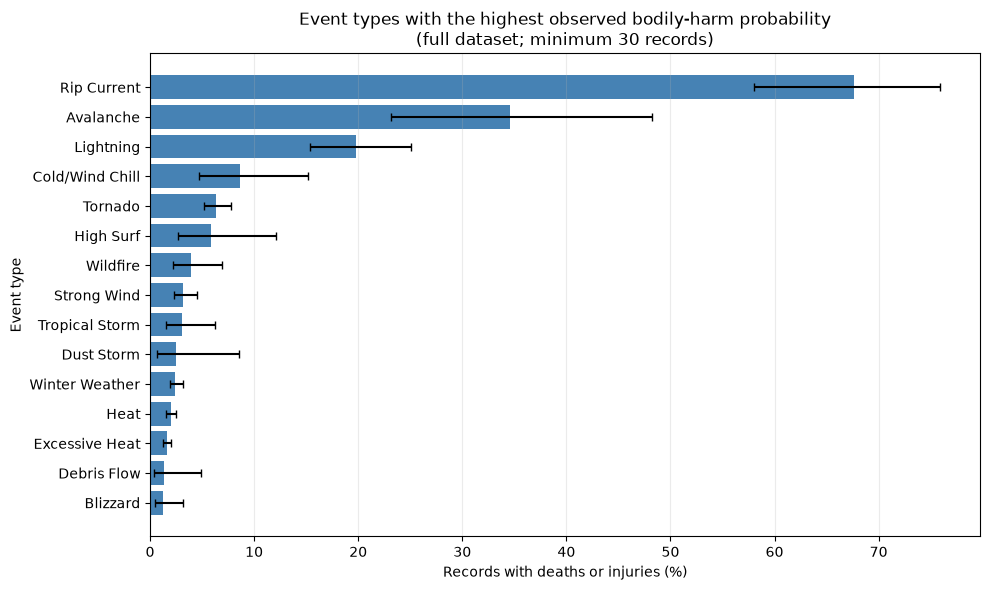

In [11]:
# Empirical probability of bodily harm by event type (June–August 2023)
harm_probability = (
    summer.assign(caused_harm=(summer["deaths"] + summer["injuries"]) > 0)
    .groupby("event_type")
    .agg(
        events=("caused_harm", "size"),
        harmful_events=("caused_harm", "sum"),
    )
    .query("events >= 30")
    .assign(probability=lambda d: d["harmful_events"] / d["events"])
    .sort_values("probability", ascending=False)
)

# Wilson 95% confidence intervals for the estimated probabilities
n = harm_probability["events"].to_numpy()
p = harm_probability["probability"].to_numpy()
z = 1.96
denominator = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / denominator
margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator

harm_probability["ci_lower"] = center - margin
harm_probability["ci_upper"] = center + margin

display(
    harm_probability.head(15).assign(
        probability_pct=lambda d: (100 * d["probability"]).round(1),
        ci_95_pct=lambda d: (
            "[" + (100 * d["ci_lower"]).round(1).astype(str)
            + "%, " + (100 * d["ci_upper"]).round(1).astype(str) + "%]"
        ),
    )[["events", "harmful_events", "probability_pct", "ci_95_pct"]]
)

# Plot the 15 highest estimated probabilities
chart = harm_probability.head(15).sort_values("probability")
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(chart.index, chart["probability"] * 100, color="steelblue")
ax.errorbar(
    chart["probability"] * 100,
    chart.index,
    xerr=[
        (chart["probability"] - chart["ci_lower"]) * 100,
        (chart["ci_upper"] - chart["probability"]) * 100,
    ],
    fmt="none",
    ecolor="black",
    capsize=3,
)

ax.set_xlabel("Records with deaths or injuries (%)")
ax.set_ylabel("Event type")
ax.set_title("Event types with the highest observed bodily-harm probability\n"
             "(June–August 2023; minimum 30 records)")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
# Empirical probability of bodily harm by event type across the full dataset
all_events = pd.read_sql_query(
    """
    SELECT
        EVENT_TYPE AS event_type,
        COALESCE(DEATHS_DIRECT, 0) + COALESCE(DEATHS_INDIRECT, 0) AS deaths,
        COALESCE(INJURIES_DIRECT, 0) + COALESCE(INJURIES_INDIRECT, 0) AS injuries
    FROM StormEvents
    WHERE EVENT_TYPE IS NOT NULL
    """,
    connection,
)

all_events["caused_harm"] = (all_events["deaths"] + all_events["injuries"]) > 0

harm_probability = (
    all_events.groupby("event_type")
    .agg(
        events=("caused_harm", "size"),
        harmful_events=("caused_harm", "sum"),
    )
    .query("events >= 30")
    .assign(probability=lambda d: d["harmful_events"] / d["events"])
    .sort_values("probability", ascending=False)
)

# Wilson 95% confidence intervals
n = harm_probability["events"].to_numpy()
p = harm_probability["probability"].to_numpy()
z = 1.96
denominator = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / denominator
margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator

harm_probability["ci_lower"] = center - margin
harm_probability["ci_upper"] = center + margin

display(
    harm_probability.head(15)
    .reset_index()
    .assign(
        probability_pct=lambda d: (100 * d["probability"]).round(1),
        ci_95_pct=lambda d: (
            "[" + (100 * d["ci_lower"]).round(1).astype(str)
            + "%, " + (100 * d["ci_upper"]).round(1).astype(str) + "%]"
        ),
    )[["event_type", "events", "harmful_events", "probability_pct", "ci_95_pct"]]
)

# Plot the 15 highest estimated probabilities
chart = harm_probability.head(15).sort_values("probability")
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(chart.index, chart["probability"] * 100, color="steelblue")
ax.errorbar(
    chart["probability"] * 100,
    chart.index,
    xerr=[
        (chart["probability"] - chart["ci_lower"]) * 100,
        (chart["ci_upper"] - chart["probability"]) * 100,
    ],
    fmt="none",
    ecolor="black",
    capsize=3,
)

ax.set_xlabel("Records with deaths or injuries (%)")
ax.set_ylabel("Event type")
ax.set_title(
    "Event types with the highest observed bodily-harm probability\n"
    "(full dataset; minimum 30 records)"
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()